# Klasifikasi Kesegaran Buah

**Anggota kelompok**
- Carlos Leonardo J. Dongoran
- Joni Fernando
- Matthew Rivandi
- Percaya Mendrova
- Yohanes Cornelius Willfredi Simanjuntak

Rincian pembagian kerja ada di `docs/pembagian_tugas.md`.

## Pembagian tugas

| Anggota | Tugas sementara |
|---|---|
| Carlos Leonardo J. Dongoran | Sementara mengerjakan persiapan dan eksplorasi awal notebook (bagian 1–5). |
| Joni Fernando | Belum ditentukan; pembagian tugas menyusul. |
| Matthew Rivandi | Belum ditentukan; pembagian tugas menyusul. |
| Percaya Mendrova | Belum ditentukan; pembagian tugas menyusul. |
| Yohanes Cornelius Willfredi Simanjuntak | Belum ditentukan; pembagian tugas menyusul. |

Pembagian tugas anggota lainnya akan ditetapkan kemudian. Rincian status sementara ada di `docs/pembagian_tugas.md`.

## 1. Import library, seed, versi TensorFlow, GPU, dan konfigurasi

Seed digunakan agar pemilihan contoh gambar dan eksperimen lebih mudah diulang. Sel setup menampilkan versi TensorFlow dan GPU yang tersedia; TensorFlow bersifat opsional untuk tahap eksplorasi dataset. Ubah konfigurasi sesuai kebutuhan.

In [ ]:
from pathlib import Path
import math
import random
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image, UnidentifiedImageError

try:
    import tensorflow as tf
except ModuleNotFoundError as error:
    if error.name != "tensorflow":
        raise
    tf = None

BENIH_ACAK = 42
UKURAN_GAMBAR = (224, 224)
UKURAN_BATCH = 32
JUMLAH_EPOCH = 20
LAJU_BELAJAR = 1e-4
CONTOH_PER_KELAS = 1

random.seed(BENIH_ACAK)
np.random.seed(BENIH_ACAK)
if tf is not None:
    tf.random.set_seed(BENIH_ACAK)

FOLDER_PROYEK = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FOLDER_DATA_ASLI = FOLDER_PROYEK / "data" / "raw"
FOLDER_DATA_OLAHAN = FOLDER_PROYEK / "data" / "processed"
FOLDER_DATASET = FOLDER_DATA_OLAHAN / "Fruits Dataset"
FOLDER_MODEL = FOLDER_PROYEK / "models"
FOLDER_GAMBAR_HASIL = FOLDER_PROYEK / "results" / "figures"
LOKASI_ARSIP_DATA = FOLDER_DATA_ASLI / "Fruits Dataset.zip"

for folder_hasil in (FOLDER_DATA_OLAHAN, FOLDER_MODEL, FOLDER_GAMBAR_HASIL):
    folder_hasil.mkdir(parents=True, exist_ok=True)

def simpan_gambar_jika_belum_ada(fig, nama_file):
    lokasi_gambar = FOLDER_GAMBAR_HASIL / nama_file
    if lokasi_gambar.is_file():
        print(f"Grafik sudah ada, tidak ditimpa: {lokasi_gambar}")
        return
    fig.savefig(lokasi_gambar, dpi=150, bbox_inches="tight")
    print(f"Grafik disimpan: {lokasi_gambar}")

print(f"Benih acak: {BENIH_ACAK}")
if tf is None:
    print("TensorFlow belum terpasang; pemeriksaan versi dan GPU dilewati.")
else:
    print(f"Versi TensorFlow: {tf.__version__}")
    daftar_gpu = tf.config.list_physical_devices("GPU")
    print(f"GPU terdeteksi: {len(daftar_gpu)}")
    for gpu in daftar_gpu:
        print(f"- {gpu.name}")
print(f"Ukuran gambar: {UKURAN_GAMBAR}")
print(f"Ukuran batch: {UKURAN_BATCH} | Epoch: {JUMLAH_EPOCH} | Laju belajar: {LAJU_BELAJAR}")
print(f"Arsip dataset: {LOKASI_ARSIP_DATA}")

Benih acak: 42
TensorFlow belum terpasang; pemeriksaan versi dan GPU dilewati.
Ukuran gambar: (224, 224)
Ukuran batch: 32 | Epoch: 20 | Laju belajar: 0.0001
Arsip dataset: d:\231111859\latihan python\nyawit_Proyek1\data\raw\Fruits Dataset.zip


## 2. Ekstrak dan muat dataset

Arsip `Fruits Dataset.zip` sudah tersedia di `data/raw/`. Sel di bawah mengekstrak gambar ke `data/processed/Fruits Dataset/`, lalu membentuk tabel berisi jalur dan label setiap gambar. Arsip berisi folder `Original Image/` dan 16 kelas: delapan jenis buah dengan kondisi `Fresh` atau `Rotten`. Arsip ini tidak menyediakan pemisahan train/test.

In [ ]:
if not LOKASI_ARSIP_DATA.is_file():
    raise FileNotFoundError(
        f"Arsip dataset tidak ditemukan: {LOKASI_ARSIP_DATA}. "
        "Pastikan Fruits Dataset.zip tersedia di folder data/raw/."
    )

EKSTENSI_GAMBAR = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
STATUS_BUAH = {"Fresh": "Segar", "Rotten": "Busuk"}
NAMA_BUAH = {
    "Apple": "Apel",
    "Banana": "Pisang",
    "Grape": "Anggur",
    "Guava": "Jambu biji",
    "Jujube": "Bidara",
    "Orange": "Jeruk",
    "Pomegranate": "Delima",
    "Strawberry": "Stroberi",
}

FOLDER_DATASET.mkdir(parents=True, exist_ok=True)
with ZipFile(LOKASI_ARSIP_DATA) as arsip:
    arsip.extractall(FOLDER_DATASET)

daftar_gambar = sorted(
    lokasi_gambar
    for lokasi_gambar in FOLDER_DATASET.rglob("*")
    if lokasi_gambar.is_file() and lokasi_gambar.suffix.lower() in EKSTENSI_GAMBAR
)

if not daftar_gambar:
    raise ValueError(
        "Gambar tidak ditemukan. Periksa apakah ZIP berisi folder kelas "
        "di dalam folder hasil ekstraksi."
    )

baris_data = []
for lokasi_gambar in daftar_gambar:
    nama_kelas = lokasi_gambar.parent.name
    status_asli = next(
        (status for status in STATUS_BUAH if nama_kelas.startswith(status)), None
    )
    if status_asli is None:
        raise ValueError(f"Format nama kelas tidak dikenal: {nama_kelas}")

    jenis_buah_asli = nama_kelas[len(status_asli):]
    if jenis_buah_asli not in NAMA_BUAH:
        raise ValueError(f"Jenis buah tidak dikenal: {nama_kelas}")

    status = STATUS_BUAH[status_asli]
    buah = NAMA_BUAH[jenis_buah_asli]
    baris_data.append(
        {
            "lokasi": str(lokasi_gambar),
            "kelas_asli": nama_kelas,
            "status": status,
            "buah": buah,
            "kelas": f"{status} {buah}",
        }
    )

data_gambar = pd.DataFrame(baris_data).sort_values(
    ["status", "buah", "lokasi"], ignore_index=True
)
daftar_kelas = sorted(data_gambar["kelas"].unique())
print(f"Jumlah gambar: {len(data_gambar):,}")
print(f"Jumlah kelas: {len(daftar_kelas)}")
print(f"Jenis buah: {', '.join(sorted(data_gambar['buah'].unique()))}")
print(f"Kondisi: {', '.join(sorted(data_gambar['status'].unique()))}")
data_gambar.head()

Jumlah gambar: 3,200
Jumlah kelas: 16
Jenis buah: Anggur, Apel, Bidara, Delima, Jambu biji, Jeruk, Pisang, Stroberi
Kondisi: Busuk, Segar


,lokasi,kelas_asli,status,buah,kelas
0,d:\231111859\latihan python\nyawit_Proyek1\dat...,RottenGrape,Busuk,Anggur,Busuk Anggur
1,d:\231111859\latihan python\nyawit_Proyek1\dat...,RottenGrape,Busuk,Anggur,Busuk Anggur
2,d:\231111859\latihan python\nyawit_Proyek1\dat...,RottenGrape,Busuk,Anggur,Busuk Anggur
3,d:\231111859\latihan python\nyawit_Proyek1\dat...,RottenGrape,Busuk,Anggur,Busuk Anggur
4,d:\231111859\latihan python\nyawit_Proyek1\dat...,RottenGrape,Busuk,Anggur,Busuk Anggur


## 3. Jumlah gambar per kelas

Tabel dan grafik berikut memperlihatkan jumlah gambar untuk tiap kombinasi jenis buah dan kondisi segar/busuk.

,Jumlah gambar
Kelas,
Busuk Anggur,200
Busuk Apel,200
Busuk Bidara,200
Busuk Delima,200
Busuk Jambu biji,200
Busuk Jeruk,200
Busuk Pisang,200
Busuk Stroberi,200
Segar Anggur,200


Grafik sudah ada, tidak ditimpa: d:\231111859\latihan python\nyawit_Proyek1\results\figures\jumlah_gambar_per_kelas.png


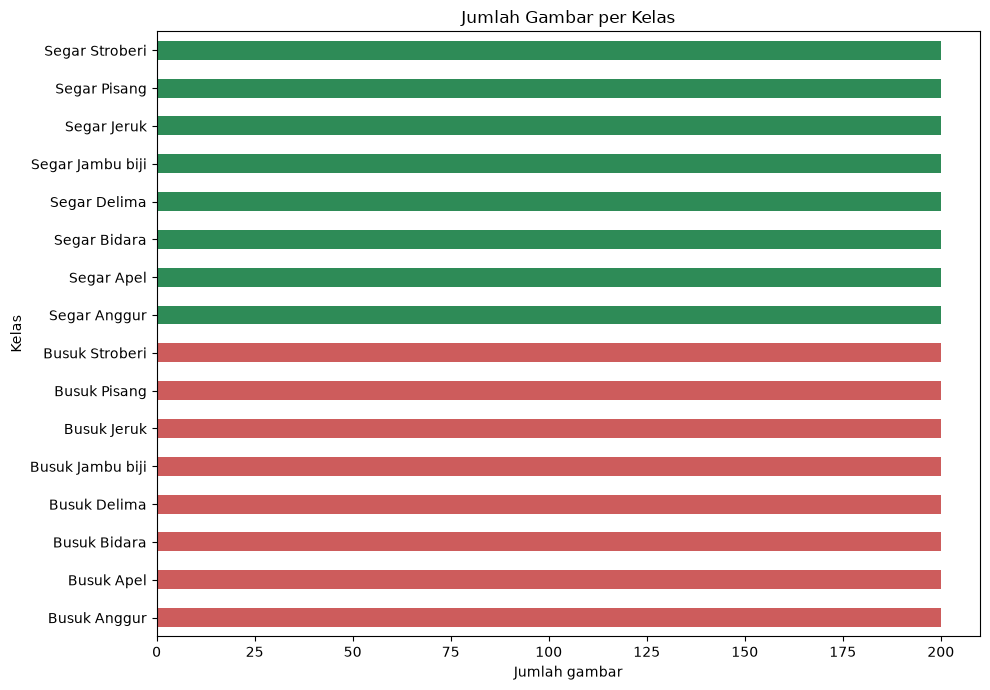

In [ ]:
jumlah_per_kelas = (
    data_gambar["kelas"]
    .value_counts()
    .reindex(daftar_kelas, fill_value=0)
    .rename_axis("Kelas")
    .to_frame("Jumlah gambar")
)
display(jumlah_per_kelas)

warna_kelas = [
    "seagreen" if nama_kelas.startswith("Segar") else "indianred"
    for nama_kelas in jumlah_per_kelas.index
]
jumlah_per_kelas["Jumlah gambar"].plot(
    kind="barh", figsize=(10, 7), color=warna_kelas
)
plt.title("Jumlah Gambar per Kelas")
plt.xlabel("Jumlah gambar")
plt.ylabel("Kelas")
plt.tight_layout()
simpan_gambar_jika_belum_ada(plt.gcf(), "jumlah_gambar_per_kelas.png")
plt.show()

## 4. Pemeriksaan resolusi dan format gambar

Periksa metadata seluruh gambar, tampilkan jumlah per format, serta resolusi yang paling sering ditemukan.

In [ ]:
metadata_gambar = []
gambar_tidak_valid = []

for baris in data_gambar.itertuples(index=False):
    try:
        with Image.open(baris.lokasi) as gambar:
            metadata_gambar.append(
                {
                    "format": gambar.format,
                    "lebar": gambar.width,
                    "tinggi": gambar.height,
                    "resolusi": f"{gambar.width} x {gambar.height}",
                }
            )
    except (UnidentifiedImageError, OSError) as error:
        gambar_tidak_valid.append({"lokasi": baris.lokasi, "error": str(error)})

if gambar_tidak_valid:
    print(f"Gambar tidak dapat dibaca: {len(gambar_tidak_valid)}")
    display(pd.DataFrame(gambar_tidak_valid))

ringkasan_metadata = pd.DataFrame(metadata_gambar)
if ringkasan_metadata.empty:
    raise ValueError("Tidak ada metadata gambar yang berhasil dibaca.")

print(f"Gambar berhasil diperiksa: {len(ringkasan_metadata):,}")
print(f"Jumlah resolusi unik: {ringkasan_metadata['resolusi'].nunique():,}")
print("Jumlah gambar per format:")
display(
    ringkasan_metadata["format"]
    .value_counts()
    .rename_axis("Format")
    .to_frame("Jumlah gambar")
)
print("10 resolusi yang paling sering ditemukan:")
display(
    ringkasan_metadata["resolusi"]
    .value_counts()
    .head(10)
    .rename_axis("Resolusi (lebar x tinggi)")
    .to_frame("Jumlah gambar")
)
print(
    "Rentang dimensi: "
    f"lebar {ringkasan_metadata['lebar'].min()}-"
    f"{ringkasan_metadata['lebar'].max()} px, "
    f"tinggi {ringkasan_metadata['tinggi'].min()}-"
    f"{ringkasan_metadata['tinggi'].max()} px"
)

Gambar berhasil diperiksa: 3,200
Jumlah resolusi unik: 2,274
Jumlah gambar per format:


,Jumlah gambar
Format,
JPEG,3200


10 resolusi yang paling sering ditemukan:


,Jumlah gambar
Resolusi (lebar x tinggi),
2560 x 1920,223
1920 x 2560,93
1200 x 1600,87
1600 x 1200,50
1040 x 780,18
577 x 433,17
780 x 1040,12
433 x 577,8
2560 x 2242,5


Rentang dimensi: lebar 251-2560 px, tinggi 301-2560 px


## 5. Contoh gambar setiap kelas

Tampilkan satu contoh gambar untuk setiap kombinasi jenis buah dan kondisi.

Grafik sudah ada, tidak ditimpa: d:\231111859\latihan python\nyawit_Proyek1\results\figures\contoh_gambar_buah.png


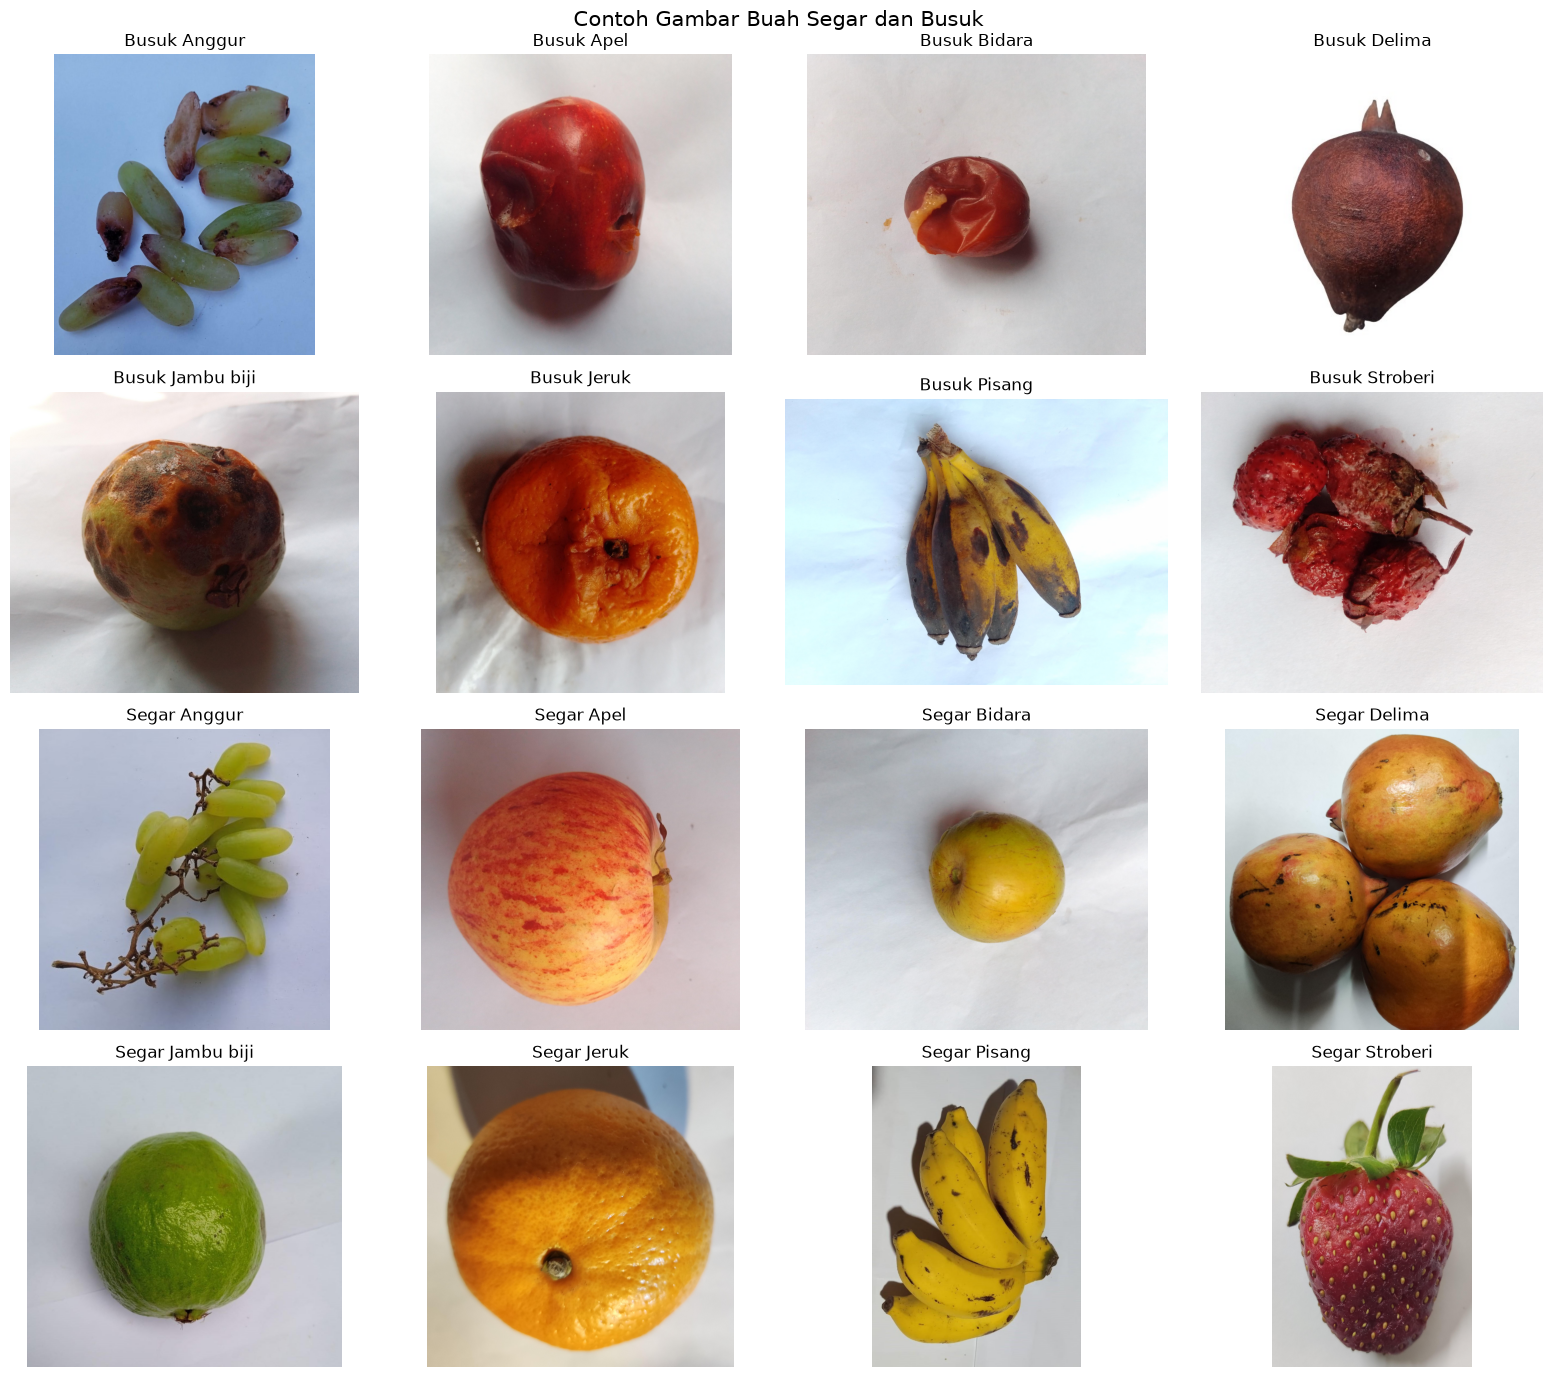

In [ ]:
jumlah_contoh = min(
    CONTOH_PER_KELAS,
    int(data_gambar.groupby("kelas").size().min()),
)
contoh_gambar = (
    data_gambar.groupby("kelas", group_keys=False)
    .sample(n=jumlah_contoh, random_state=BENIH_ACAK)
    .reset_index(drop=True)
)

jumlah_kolom = min(4, len(daftar_kelas))
jumlah_baris = math.ceil(len(daftar_kelas) / jumlah_kolom)
fig, axes = plt.subplots(
    jumlah_baris,
    jumlah_kolom,
    figsize=(4 * jumlah_kolom, 3.5 * jumlah_baris),
    squeeze=False,
)

for nomor, nama_kelas in enumerate(daftar_kelas):
    sumbu = axes.flat[nomor]
    pilihan = contoh_gambar[contoh_gambar["kelas"] == nama_kelas].iloc[0]
    with Image.open(pilihan["lokasi"]) as gambar:
        sumbu.imshow(gambar.convert("RGB"))
    sumbu.set_title(nama_kelas)
    sumbu.axis("off")

for sumbu in axes.flat[len(daftar_kelas):]:
    sumbu.axis("off")

fig.suptitle("Contoh Gambar Buah Segar dan Busuk", fontsize=15)
fig.tight_layout()
simpan_gambar_jika_belum_ada(fig, "contoh_gambar_buah.png")
plt.show()

## 6. Praproses data

buang gambar rusak dan duplikat, cek kelas timpang, bagi data jadi train/val/test, cek kebocoran data, lalu simpan ke `split.csv`. File gambar asli tidak dihapus, hanya dikeluarkan dari tabel dan dicatat di `gambar_dibuang.csv`


In [ ]:
import hashlib
import json

# Konfigurasi praproses
RASIO_TRAIN = 0.70
RASIO_VAL = 0.15
RASIO_TEST = 0.15
AMBANG_MIRIP = 3          # jarak Hamming dHash maksimum agar dua gambar dianggap hampir sama
SISI_MINIMAL = 32         # gambar dengan sisi lebih kecil dari ini dianggap rusak
RASIO_TIMPANG_MAKS = 1.5  # batas rasio kelas terbesar : terkecil sebelum bobot kelas dipakai

assert abs(RASIO_TRAIN + RASIO_VAL + RASIO_TEST - 1.0) < 1e-9, "Total rasio split harus 1"

indeks_kelas = {nama: nomor for nomor, nama in enumerate(daftar_kelas)}
print(f"Rasio split (train/val/test): {RASIO_TRAIN:.0%} / {RASIO_VAL:.0%} / {RASIO_TEST:.0%}")

Rasio split (train/val/test): 70% / 15% / 15%


### 7. Cek gambar rusak

Setiap gambar dibuka sampai selesai supaya file yang korup atau terpotong ketahuan. Sekalian dihitung MD5 dan dHash untuk dipakai di cek duplikat. Hasilnya: dari 3.200 gambar, tidak ada yang rusak.

In [ ]:
def hitung_md5(lokasi):
    hasil = hashlib.md5()
    with open(lokasi, "rb") as berkas:
        for potongan in iter(lambda: berkas.read(1 << 20), b""):
            hasil.update(potongan)
    return hasil.hexdigest()


def hitung_dhash(gambar):
    # dHash 64 bit: bandingkan piksel bertetangga pada versi 9x8 yang digrayscale
    kecil = gambar.convert("L").resize((9, 8), Image.LANCZOS)
    piksel = np.asarray(kecil, dtype=np.int16)
    return (piksel[:, 1:] > piksel[:, :-1]).flatten()


def periksa_gambar(lokasi):
    # Mengembalikan (dhash, None) bila sehat, atau (None, alasan) bila rusak
    try:
        with Image.open(lokasi) as gambar:
            gambar.verify()
        with Image.open(lokasi) as gambar:
            if min(gambar.size) < SISI_MINIMAL:
                return None, "ukuran terlalu kecil"
            gambar.draft("RGB", (256, 256))  # percepat decode JPEG besar
            gambar.load()
            return hitung_dhash(gambar), None
    except (UnidentifiedImageError, OSError, SyntaxError, ValueError) as error:
        return None, f"{type(error).__name__}: {error}"


daftar_md5 = []
daftar_alasan = []
dhash_gambar = {}

for nomor, lokasi in enumerate(data_gambar["lokasi"], start=1):
    dhash, alasan = periksa_gambar(lokasi)
    daftar_alasan.append(alasan)
    if alasan is None:
        dhash_gambar[lokasi] = dhash
        daftar_md5.append(hitung_md5(lokasi))
    else:
        daftar_md5.append(None)
    if nomor % 500 == 0 or nomor == len(data_gambar):
        print(f"Diperiksa: {nomor:,}/{len(data_gambar):,}")

data_periksa = data_gambar.copy()
data_periksa["md5"] = daftar_md5
data_periksa["alasan_rusak"] = daftar_alasan

gambar_rusak = data_periksa[data_periksa["alasan_rusak"].notna()]
print(f"Gambar rusak: {len(gambar_rusak)}")
if len(gambar_rusak) > 0:
    display(gambar_rusak[["lokasi", "kelas", "alasan_rusak"]])

Diperiksa: 500/3,200
Diperiksa: 1,000/3,200
Diperiksa: 1,500/3,200
Diperiksa: 2,000/3,200
Diperiksa: 2,500/3,200
Diperiksa: 3,000/3,200
Diperiksa: 3,200/3,200
Gambar rusak: 0


### 8. Deteksi dan pembuangan duplikat

Duplikat dicek dengan tiga cara: file yang isinya sama persis (MD5), file yang sama tapi beda kelas (semuanya dibuang karena labelnya bertentangan), dan gambar yang hampir sama dalam satu kelas (dHash). Ini dilakukan sebelum split supaya gambar yang sama tidak ada di train dan test sekaligus. Hasilnya, 36 gambar dibuang (7 duplikat persis dan 29 hampir sama), tersisa 3.164 gambar.

In [ ]:
def matriks_mirip(tabel):
    # True pada pasangan gambar sekelas dengan jarak Hamming dHash <= AMBANG_MIRIP
    lokasi_gambar = tabel["lokasi"].to_numpy()
    kelas = tabel["kelas"].to_numpy()
    bit = np.packbits(
        np.stack([dhash_gambar[lokasi] for lokasi in lokasi_gambar]), axis=1
    )
    mirip = np.zeros((len(tabel), len(tabel)), dtype=bool)

    for nama_kelas in pd.unique(kelas):
        indeks = np.flatnonzero(kelas == nama_kelas)
        bit_kelas = bit[indeks]
        xor = np.bitwise_xor(bit_kelas[:, None, :], bit_kelas[None, :, :])
        jarak = np.unpackbits(xor, axis=2).sum(axis=2)
        mirip[np.ix_(indeks, indeks)] = jarak <= AMBANG_MIRIP

    np.fill_diagonal(mirip, False)
    return mirip


catatan_dibuang = []

def catat(tabel, alasan):
    for baris in tabel.itertuples(index=False):
        catatan_dibuang.append({"lokasi": baris.lokasi, "kelas": baris.kelas, "alasan": alasan})

# Gambar rusak
catat(gambar_rusak, "gambar rusak")
data_sehat = data_periksa[data_periksa["alasan_rusak"].isna()].copy()

# Duplikat lintas kelas (isi sama, label beda)
kelas_per_md5 = data_sehat.groupby("md5")["kelas"].transform("nunique")
konflik = data_sehat[kelas_per_md5 > 1]
catat(konflik, "duplikat lintas kelas (label bertentangan)")
data_sehat = data_sehat[kelas_per_md5 == 1]

# Duplikat persis (isi sama, kelas sama)
duplikat_persis = data_sehat.duplicated("md5", keep="first")
catat(data_sehat[duplikat_persis], "duplikat persis (MD5 sama)")
data_sehat = data_sehat[~duplikat_persis].reset_index(drop=True)

# Gambar hampir sama (dalam kelas yang sama)
mirip = matriks_mirip(data_sehat)
dibuang_mirip = np.zeros(len(data_sehat), dtype=bool)
for i in range(len(data_sehat)):
    if dibuang_mirip[i]:
        continue
    tetangga = np.where(mirip[i])[0]
    dibuang_mirip[tetangga[tetangga > i]] = True
catat(data_sehat[dibuang_mirip], f"hampir sama (dHash <= {AMBANG_MIRIP})")
data_bersih = data_sehat[~dibuang_mirip].reset_index(drop=True)

log_dibuang = pd.DataFrame(catatan_dibuang, columns=["lokasi", "kelas", "alasan"])

print(f"Jumlah awal         : {len(data_gambar):,}")
print(f"Dibuang             : {len(log_dibuang):,}")
print(f"Jumlah setelah bersih: {len(data_bersih):,}")
if len(log_dibuang) > 0:
    display(
        log_dibuang["alasan"].value_counts().rename_axis("Alasan").to_frame("Jumlah gambar")
    )

Jumlah awal         : 3,200
Dibuang             : 36
Jumlah setelah bersih: 3,164


,Jumlah gambar
Alasan,
hampir sama (dHash <= 3),29
duplikat persis (MD5 sama),7


#### Cek visual gambar hampir sama

Beberapa pasangan yang dibuang ditampilkan untuk memastikan memang foto yang sama (kiri dibuang, kanan dipertahankan). Yang dipertahankan adalah gambar dengan urutan nama file paling awal

Grafik sudah ada, tidak ditimpa: d:\231111859\latihan python\nyawit_Proyek1\results\figures\contoh_gambar_hampir_sama_dibuang.png


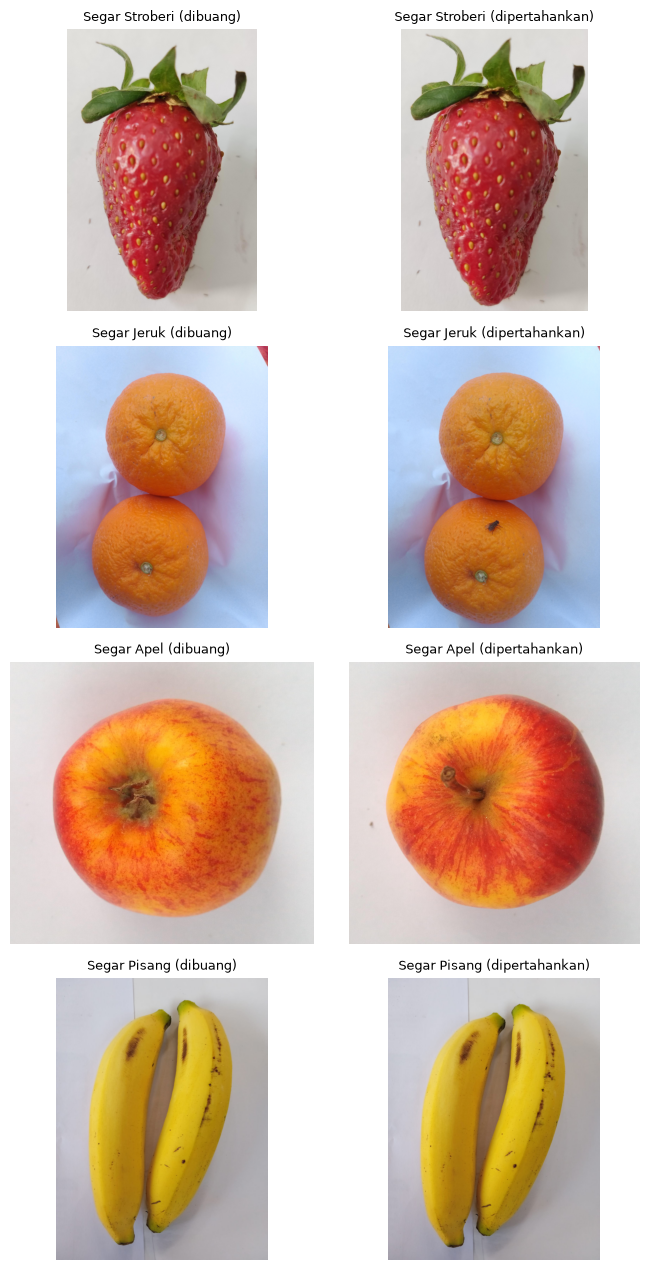

In [ ]:
# Cek visual: gambar yang dibuang (kiri) dibandingkan dengan gambar yang dipertahankan (kanan)
indeks_dibuang = np.where(dibuang_mirip)[0]
jumlah_tampil = min(4, len(indeks_dibuang))

if jumlah_tampil == 0:
    print("Tidak ada gambar hampir sama yang dibuang.")
else:
    fig, axes = plt.subplots(jumlah_tampil, 2, figsize=(7, 3.2 * jumlah_tampil), squeeze=False)
    pilihan = np.random.RandomState(BENIH_ACAK).choice(indeks_dibuang, jumlah_tampil, replace=False)
    for baris, j in enumerate(pilihan):
        pasangan = [i for i in np.where(mirip[j])[0] if not dibuang_mirip[i]]
        i = pasangan[0]
        for kolom, (nomor, ket) in enumerate([(j, "dibuang"), (i, "dipertahankan")]):
            with Image.open(data_sehat.loc[nomor, "lokasi"]) as gambar:
                axes[baris, kolom].imshow(gambar.convert("RGB"))
            axes[baris, kolom].set_title(f"{data_sehat.loc[nomor, 'kelas']} ({ket})", fontsize=9)
            axes[baris, kolom].axis("off")
    fig.tight_layout()
    simpan_gambar_jika_belum_ada(fig, "contoh_gambar_hampir_sama_dibuang.png")
    plt.show()

### 9. Penanganan kelas timpang

Jumlah gambar tiap kelas hampir sama, jadi data ini tidak timpang dan tidak perlu oversampling atau undersampling. Oversampling sebelum split juga bisa membuat salinan gambar masuk ke train dan test. Untuk menjaga proporsi kelas, split dibuat per kelas (stratified). Bobot kelas hanya dipakai kalau rasio kelas terbesar dan terkecil lebih dari 1,5.

In [ ]:
jumlah_kelas = data_bersih["kelas"].value_counts().reindex(daftar_kelas, fill_value=0)
rasio_timpang = jumlah_kelas.max() / max(jumlah_kelas.min(), 1)

if jumlah_kelas.min() < 10:
    raise ValueError(
        "Ada kelas dengan kurang dari 10 gambar setelah pembersihan: "
        f"{jumlah_kelas.idxmin()} ({jumlah_kelas.min()}). Periksa ulang tahap pembersihan."
    )

pakai_bobot_kelas = bool(rasio_timpang > RASIO_TIMPANG_MAKS)

print(f"Gambar per kelas: min {jumlah_kelas.min()}, maks {jumlah_kelas.max()}")
print(f"Rasio kelas terbesar : terkecil = {rasio_timpang:.2f}")
if pakai_bobot_kelas:
    print("Kelas timpang -> bobot kelas dipakai (dihitung dari data train).")
else:
    print("Kelas relatif seimbang -> tanpa resampling, bobot kelas = 1.")

Gambar per kelas: min 188, maks 200
Rasio kelas terbesar : terkecil = 1.06
Kelas relatif seimbang -> tanpa resampling, bobot kelas = 1.


### 10. Pembagian data train / val / test

Pembagian 70% / 15% / 15% dipilih karena tiap kelas hanya sekitar 200 gambar. Dengan porsi ini train tetap cukup besar (sekitar 140 gambar per kelas), sedangkan val dan test masing-masing sekitar 30 gambar per kelas. Porsi 80/10/10 akan menyisakan hanya sekitar 20 gambar per kelas di val/test, sehingga hasil evaluasinya terlalu berfluktuasi.

Pembagian dilakukan per kelas (stratified) dengan seed `BENIH_ACAK` agar hasilnya bisa diulang.

split,train,val,test
kelas,,,
Busuk Anggur,139,30,30
Busuk Apel,139,30,30
Busuk Bidara,140,30,30
Busuk Delima,136,29,29
Busuk Jambu biji,138,30,30
Busuk Jeruk,139,30,30
Busuk Pisang,140,30,30
Busuk Stroberi,140,30,30
Segar Anggur,139,30,30


Grafik sudah ada, tidak ditimpa: d:\231111859\latihan python\nyawit_Proyek1\results\figures\jumlah_gambar_per_split.png


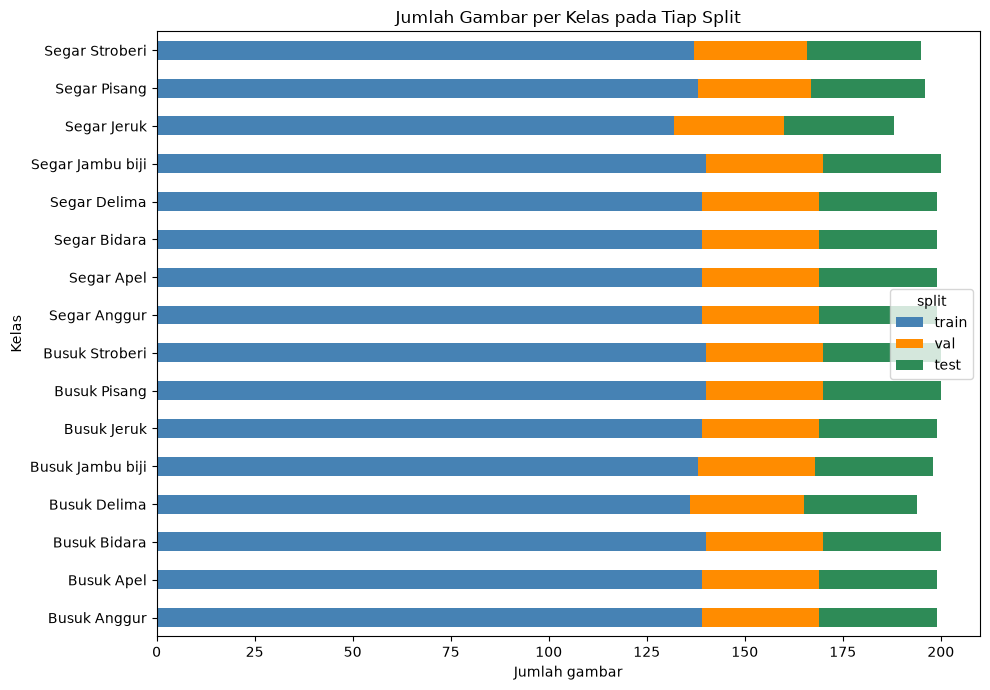

In [ ]:
urutan_split = ["train", "val", "test"]
bagian_data = []

for nama_kelas, kelompok in data_bersih.groupby("kelas"):
    kelompok = kelompok.sample(frac=1, random_state=BENIH_ACAK).copy()
    n = len(kelompok)
    n_test = max(1, round(n * RASIO_TEST))
    n_val = max(1, round(n * RASIO_VAL))
    n_train = n - n_val - n_test
    kelompok["split"] = ["test"] * n_test + ["val"] * n_val + ["train"] * n_train
    bagian_data.append(kelompok)

data_split = pd.concat(bagian_data, ignore_index=True)
data_split["label"] = data_split["kelas"].map(indeks_kelas)
data_split["split"] = pd.Categorical(data_split["split"], categories=urutan_split, ordered=True)
data_split = data_split.sort_values(["split", "kelas", "lokasi"], ignore_index=True)
data_split["split"] = data_split["split"].astype(str)

# Bobot kelas: hanya dari data train
jumlah_train = data_split[data_split["split"] == "train"]["kelas"].value_counts()
if pakai_bobot_kelas:
    bobot_kelas = {
        indeks_kelas[k]: float(jumlah_train.sum() / (len(daftar_kelas) * jumlah_train[k]))
        for k in daftar_kelas
    }
else:
    bobot_kelas = {indeks_kelas[k]: 1.0 for k in daftar_kelas}

tabel_split = pd.crosstab(data_split["kelas"], data_split["split"])[urutan_split]
tabel_split.loc["Total"] = tabel_split.sum()
display(tabel_split)

pd.crosstab(data_split["kelas"], data_split["split"])[urutan_split].plot(
    kind="barh", stacked=True, figsize=(10, 7),
    color=["steelblue", "darkorange", "seagreen"],
)
plt.title("Jumlah Gambar per Kelas pada Tiap Split")
plt.xlabel("Jumlah gambar")
plt.ylabel("Kelas")
plt.tight_layout()
simpan_gambar_jika_belum_ada(plt.gcf(), "jumlah_gambar_per_split.png")
plt.show()

### 11.  Pemeriksaan kebocoran data antar split

Empat hal diperiksa: tidak ada file yang sama di dua split, tidak ada isi file (MD5) yang sama di dua split, tidak ada gambar hampir sama (dHash) lintas split dalam kelas yang sama, dan setiap kelas muncul di ketiga split. Jika ada yang gagal, sel ini berhenti dengan pesan error.

In [ ]:
pasangan_split = [("train", "val"), ("train", "test"), ("val", "test")]
lokasi_split = {s: set(data_split.loc[data_split["split"] == s, "lokasi"]) for s in urutan_split}
md5_split = {s: set(data_split.loc[data_split["split"] == s, "md5"]) for s in urutan_split}

# 1. Tidak ada file yang sama di dua split
for a, b in pasangan_split:
    irisan = lokasi_split[a] & lokasi_split[b]
    assert not irisan, f"Ada {len(irisan)} file yang sama di {a} dan {b}"

# 2. Tidak ada isi file (MD5) yang sama di dua split
for a, b in pasangan_split:
    irisan = md5_split[a] & md5_split[b]
    assert not irisan, f"Ada {len(irisan)} isi file (MD5) yang sama di {a} dan {b}"

# 3. Tidak ada gambar hampir sama lintas split (dalam kelas yang sama)
mirip_akhir = matriks_mirip(data_split)
label_split = data_split["split"].to_numpy()
lintas_split = mirip_akhir & (label_split[:, None] != label_split[None, :])
assert not lintas_split.any(), f"Ada {int(lintas_split.sum() // 2)} pasangan gambar mirip lintas split"

# 4. Semua kelas ada di ketiga split, dan tidak ada gambar yang hilang atau ganda
assert (tabel_split.drop(index="Total") > 0).all().all(), "Ada kelas yang kosong di salah satu split"
assert data_split["lokasi"].is_unique, "Ada gambar ganda di tabel split"
assert len(data_split) == len(data_bersih), "Jumlah gambar setelah split tidak sama dengan data bersih"

print("Tidak ada kebocoran data antar split.")
print(f"- Jalur file bertabrakan   : 0")
print(f"- Isi file (MD5) sama      : 0")
print(f"- Gambar mirip lintas split: 0")
print(f"- Semua {len(daftar_kelas)} kelas ada di train, val, dan test")

Tidak ada kebocoran data antar split.
- Jalur file bertabrakan   : 0
- Isi file (MD5) sama      : 0
- Gambar mirip lintas split: 0
- Semua 16 kelas ada di train, val, dan test


### 12. Simpan hasil praproses

Kolom `lokasi` di `split.csv` disimpan sebagai jalur relatif terhadap folder proyek, jadi file ini tetap bisa dipakai di komputer anggota lain. Untuk membaca gambar: `FOLDER_PROYEK / lokasi`.

In [ ]:
data_simpan = data_split.copy()
data_simpan["lokasi"] = data_simpan["lokasi"].map(
    lambda jalur: Path(jalur).relative_to(FOLDER_PROYEK).as_posix()
)
data_simpan = data_simpan[
    ["lokasi", "kelas_asli", "status", "buah", "kelas", "label", "split", "md5"]
]

lokasi_split_csv = FOLDER_DATA_OLAHAN / "split.csv"
lokasi_log_dibuang = FOLDER_DATA_OLAHAN / "gambar_dibuang.csv"
lokasi_bobot = FOLDER_DATA_OLAHAN / "bobot_kelas.json"

data_simpan.to_csv(lokasi_split_csv, index=False)

log_simpan = log_dibuang.copy()
log_simpan["lokasi"] = log_simpan["lokasi"].map(
    lambda jalur: Path(jalur).relative_to(FOLDER_PROYEK).as_posix()
)
log_simpan.to_csv(lokasi_log_dibuang, index=False)

with open(lokasi_bobot, "w", encoding="utf-8") as berkas:
    json.dump(
        {"indeks_kelas": indeks_kelas, "bobot_kelas": {str(k): v for k, v in bobot_kelas.items()}},
        berkas, ensure_ascii=False, indent=2,
    )

# Baca ulang untuk memastikan file tersimpan dengan benar
cek = pd.read_csv(lokasi_split_csv)
assert len(cek) == len(data_split), "Jumlah baris split.csv tidak sesuai"
assert set(cek["split"]) == set(urutan_split), "Nama split pada split.csv tidak sesuai"
assert all((FOLDER_PROYEK / jalur).is_file() for jalur in cek["lokasi"]), "Ada jalur gambar yang tidak ditemukan"

print(f"split.csv         : {lokasi_split_csv} ({len(cek):,} baris)")
print(f"gambar_dibuang.csv: {lokasi_log_dibuang} ({len(log_simpan):,} baris)")
print(f"bobot_kelas.json  : {lokasi_bobot}")
print("Jumlah gambar per split:")
display(cek["split"].value_counts().reindex(urutan_split).rename_axis("Split").to_frame("Jumlah gambar"))

split.csv         : d:\231111859\latihan python\nyawit_Proyek1\data\processed\split.csv (3,164 baris)
gambar_dibuang.csv: d:\231111859\latihan python\nyawit_Proyek1\data\processed\gambar_dibuang.csv (36 baris)
bobot_kelas.json  : d:\231111859\latihan python\nyawit_Proyek1\data\processed\bobot_kelas.json
Jumlah gambar per split:


,Jumlah gambar
Split,
train,2214
val,475
test,475


### 13. Input Pipeline tf.data (Matthew Rivandy)
Bagian ini membuat "jalur" (input pipeline) yang menyiapkan gambar sebelum masuk ke model. Sumbernya `split.csv` hasil praproses di bagian 12, jadi pembagian train/val/test tidak dibuat ulang.

Alur untuk data train: baca `split.csv`, acak urutan, baca file gambar, perkecil ke 224x224, ubah nilai piksel ke rentang 0-1, bagi per batch 32, lalu augmentasi ringan. Data val dan test memakai alur yang sama tetapi tanpa pengacakan dan tanpa augmentasi, supaya hasil evaluasinya stabil dan bisa dibandingkan.

##### Cek TensorFlow dan konfigurasi
Sel berikut mengimpor TensorFlow dan menampilkan Python yang dipakai kernel, yang harus berasal dari folder `.venv` proyek. Konfigurasinya sama dengan bagian 1: ukuran gambar 224x224, batch 32, dan benih acak 42.

`FOLDER_PROYEK` dihitung dari folder kerja notebook, jadi jalur relatif di `split.csv` bisa dibaca di komputer anggota mana pun. Fungsi `simpan_gambar` menyimpan grafik ke `results/figures/`.

In [1]:
import sys
from pathlib import Path
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf

print(f"Python kernel : {sys.executable}")
print(f"TensorFlow    : {tf.__version__}")

# Konfigurasi (nilainya sama dengan bagian 1)
BENIH_ACAK = 42
UKURAN_GAMBAR = (224, 224)
UKURAN_BATCH = 32
tf.random.set_seed(BENIH_ACAK)

FOLDER_PROYEK = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FOLDER_DATA_OLAHAN = FOLDER_PROYEK / "data" / "processed"
FOLDER_DATASET = FOLDER_DATA_OLAHAN / "Fruits Dataset"
LOKASI_ARSIP_DATA = FOLDER_PROYEK / "data" / "raw" / "Fruits Dataset.zip"
LOKASI_SPLIT_CSV = FOLDER_DATA_OLAHAN / "split.csv"
FOLDER_GAMBAR_HASIL = FOLDER_PROYEK / "results" / "figures"
FOLDER_GAMBAR_HASIL.mkdir(parents=True, exist_ok=True)


def simpan_gambar(fig, nama_file):
    lokasi_gambar = FOLDER_GAMBAR_HASIL / nama_file
    fig.savefig(lokasi_gambar, dpi=150, bbox_inches="tight")
    print(f"Grafik disimpan: {lokasi_gambar}")

Python kernel : d:\fruit_freshness_classification\.venv\Scripts\python.exe
TensorFlow    : 2.21.0


##### Memastikan gambar tersedia
`split.csv` hanya berisi jalur dan label, sedangkan file gambarnya ada di `data/processed/Fruits Dataset/` dan tidak ikut di-commit ke Git. Sel berikut memeriksa bahwa semua gambar yang tercatat di `split.csv` benar-benar ada. Jika belum, gambar diekstrak dari `data/raw/Fruits Dataset.zip`, dengan folder tujuan disesuaikan terhadap susunan isi zip supaya jalurnya cocok.

Hasil yang diharapkan: 3.164 gambar ditemukan, 16 kelas, dengan train 2214, val 475, dan test 475. `nama_kelas` (pemetaan label ke nama kelas) dipakai nanti untuk judul gambar.

In [2]:
tabel_split = pd.read_csv(LOKASI_SPLIT_CSV)
urutan_split = ["train", "val", "test"]


def cari_gambar_hilang(tabel):
    return [jalur for jalur in tabel["lokasi"] if not (FOLDER_PROYEK / jalur).is_file()]


gambar_hilang = cari_gambar_hilang(tabel_split)
if gambar_hilang and LOKASI_ARSIP_DATA.is_file():
    with ZipFile(LOKASI_ARSIP_DATA) as arsip:
        isi = [n for n in arsip.namelist() if not n.startswith("__MACOSX")]
        awal = isi[0]
        print(f"Isi pertama zip: {awal}")
        # Sesuaikan tujuan ekstrak dengan susunan folder di dalam zip
        if awal.startswith("Fruits Dataset/"):
            tujuan = FOLDER_DATA_OLAHAN
        elif awal.startswith("Original Image/"):
            tujuan = FOLDER_DATASET
        else:
            tujuan = FOLDER_DATASET / "Original Image"
        print(f"{len(gambar_hilang):,} gambar belum ada, mengekstrak ke {tujuan} ...")
        tujuan.mkdir(parents=True, exist_ok=True)
        arsip.extractall(tujuan)
    gambar_hilang = cari_gambar_hilang(tabel_split)

if gambar_hilang:
    raise FileNotFoundError(
        f"{len(gambar_hilang):,} gambar di split.csv tidak ditemukan, contoh: {gambar_hilang[0]}. "
        "Pastikan 'Fruits Dataset.zip' ada di data/raw/ lalu jalankan sel ini lagi."
    )

nama_kelas = tabel_split.drop_duplicates("label").sort_values("label").set_index("label")["kelas"]
print(f"Semua {len(tabel_split):,} gambar ditemukan.")
print(f"Jumlah kelas: {len(nama_kelas)}")
print(tabel_split["split"].value_counts().reindex(urutan_split).to_string())

Semua 3,164 gambar ditemukan.
Jumlah kelas: 16
split
train    2214
val       475
test      475


##### Memeriksa isi gambar
Sebagai pengecekan tambahan, nilai MD5 dari 20 gambar acak dihitung ulang lalu dibandingkan dengan kolom `md5` di `split.csv`. Jika hasilnya 20/20, gambar di komputer ini identik dengan gambar yang dipakai saat praproses, sehingga hasil pipeline bisa dibandingkan dengan anggota kelompok lain.

In [3]:
import hashlib

contoh = tabel_split.sample(20, random_state=1)
cocok = sum(
    hashlib.md5((FOLDER_PROYEK / r.lokasi).read_bytes()).hexdigest() == r.md5
    for r in contoh.itertuples()
)
print(f"MD5 cocok: {cocok}/20")

MD5 cocok: 20/20


### Fungsi pembuat dataset
Pipeline dibangun dari tiga bagian:

- `muat_gambar`: membaca file gambar, mengubah ukurannya ke 224x224, lalu membagi nilai piksel dengan 255 sehingga rentangnya menjadi 0-1. Label diubah ke `int32`.
- `lapisan_augmentasi`: membalik gambar secara horizontal dan memutarnya sedikit (sekitar ±18°). Hanya flip dan rotasi tanpa perubahan warna, karena warna adalah petunjuk utama untuk membedakan buah segar dan busuk.
- `buat_dataset`: membaca `split.csv`, mengambil baris untuk split yang diminta, lalu menyusun pipeline. Pengacakan dan augmentasi hanya aktif untuk `"train"`.

Urutan langkahnya disengaja: jalur file diacak lebih dulu (murah, karena belum ada gambar yang dibaca), lalu gambar dibaca dan diproses, dibagi per batch, diaugmentasi per batch, dan terakhir `prefetch` supaya batch berikutnya sudah disiapkan saat model memproses batch sekarang. Label disimpan sebagai bilangan bulat 0-15 sehingga cocok dengan loss `sparse_categorical_crossentropy` nanti.

In [4]:
AUTOTUNE = tf.data.AUTOTUNE


def muat_gambar(jalur, label):
    mentah = tf.io.read_file(jalur)
    gambar = tf.io.decode_image(mentah, channels=3, expand_animations=False)
    gambar.set_shape([None, None, 3])
    gambar = tf.image.resize(gambar, UKURAN_GAMBAR)  # hasilnya float32
    gambar = gambar / 255.0                           # 0-255 -> 0-1
    return gambar, tf.cast(label, tf.int32)


lapisan_augmentasi = tf.keras.Sequential(
    [
        tf.keras.layers.RandomFlip("horizontal", seed=BENIH_ACAK),
        tf.keras.layers.RandomRotation(0.05, fill_mode="reflect", seed=BENIH_ACAK),  # 0.05 x 360° = ±18°
    ],
    name="augmentasi",
)


def buat_dataset(nama_split, augmentasi=False, lokasi_csv=LOKASI_SPLIT_CSV):
    # Baca split.csv, ambil satu split ('train', 'val', atau 'test'), lalu bangun tf.data.Dataset.
    # Pengacakan dan augmentasi hanya berlaku untuk 'train'.
    tabel = pd.read_csv(lokasi_csv)
    tabel = tabel[tabel["split"] == nama_split]
    if tabel.empty:
        raise ValueError(f"Split '{nama_split}' tidak ada di {lokasi_csv}")

    # Jalur absolut supaya tidak tergantung folder kerja notebook
    jalur = [(FOLDER_PROYEK / lokasi).as_posix() for lokasi in tabel["lokasi"]]
    label = tabel["label"].to_numpy(dtype="int32")

    ds = tf.data.Dataset.from_tensor_slices((jalur, label))
    sedang_train = nama_split == "train"
    if sedang_train:
        ds = ds.shuffle(len(tabel), seed=BENIH_ACAK, reshuffle_each_iteration=True)
    ds = ds.map(muat_gambar, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(UKURAN_BATCH)
    if sedang_train and augmentasi:
        ds = ds.map(lambda x, y: (lapisan_augmentasi(x, training=True), y), num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)

#### Membuat dataset train, val, dan test
Fungsi `buat_dataset` dipanggil tiga kali, sekali untuk tiap split. Opsi augmentasi diatur lewat `PAKAI_AUGMENTASI` dan hanya berpengaruh pada data train; ubah ke `False` untuk mematikannya, misalnya sebagai pembanding saat eksperimen.

Dengan batch 32, 2.214 gambar train menjadi 70 batch (batch terakhir lebih kecil), sedangkan val dan test masing-masing 475 gambar menjadi 15 batch. `element_spec` menunjukkan bentuk dan tipe satu elemen: gambar `(None, 224, 224, 3)` bertipe `float32` dan label `(None,)` bertipe `int32`, dengan `None` sebagai ukuran batch yang bisa berubah.

In [5]:
PAKAI_AUGMENTASI = True

dataset_train = buat_dataset("train", augmentasi=PAKAI_AUGMENTASI)
dataset_val = buat_dataset("val")
dataset_test = buat_dataset("test")

for nama, ds in [("train", dataset_train), ("val", dataset_val), ("test", dataset_test)]:
    print(f"{nama:5s}: {ds.cardinality().numpy():3d} batch | element_spec = {ds.element_spec}")
print(f"Augmentasi train: {'aktif' if PAKAI_AUGMENTASI else 'nonaktif'}")

train:  70 batch | element_spec = (TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))
val  :  15 batch | element_spec = (TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))
test :  15 batch | element_spec = (TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))
Augmentasi train: aktif


#### Cek hasil pipeline
Untuk memastikan pipeline bekerja, satu batch dari data train diambil lalu delapan gambar pertamanya ditampilkan bersama nama kelasnya. Gambar harus terlihat normal (bukan gelap atau terlalu terang) dan judulnya harus sesuai dengan buahnya. Grafik disimpan ke `results/figures/pipeline_contoh_batch_train.png`.

Grafik disimpan: d:\fruit_freshness_classification\results\figures\pipeline_contoh_batch_train.png


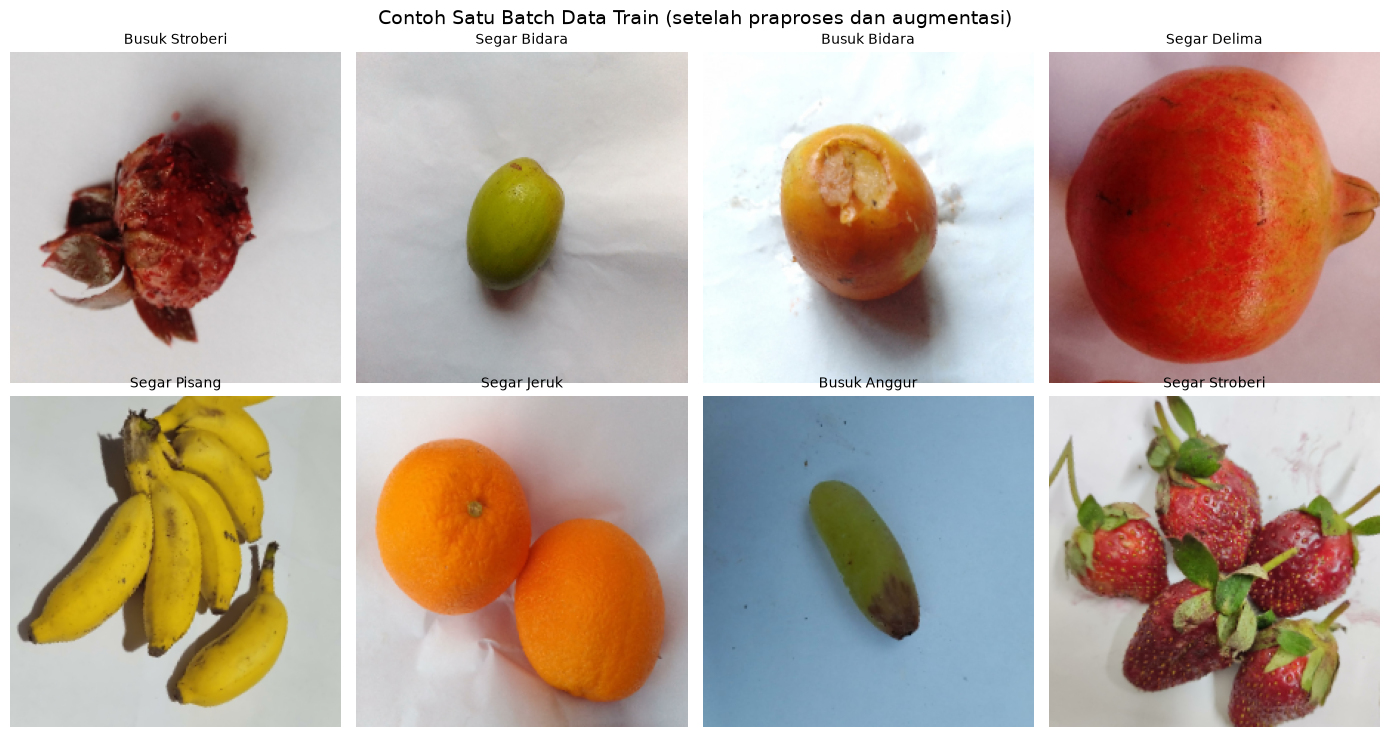

In [6]:
gambar_batch, label_batch = next(iter(dataset_train))

fig, axes = plt.subplots(2, 4, figsize=(14, 7.5))
for i, sumbu in enumerate(axes.flat):
    sumbu.imshow(gambar_batch[i].numpy())
    sumbu.set_title(nama_kelas[int(label_batch[i])], fontsize=10)
    sumbu.axis("off")
fig.suptitle("Contoh Satu Batch Data Train (setelah praproses dan augmentasi)", fontsize=14)
fig.tight_layout()
simpan_gambar(fig, "pipeline_contoh_batch_train.png")
plt.show()

Efek augmentasi dilihat dengan mengambil satu gambar train tanpa augmentasi, lalu menerapkan `lapisan_augmentasi` lima kali pada gambar yang sama. Setiap hasilnya berbeda karena balik dan sudut putarnya acak, tetapi buahnya tetap bisa dikenali dan warnanya tidak berubah. Grafik disimpan ke `results/figures/pipeline_augmentasi_vs_asli.png`.

Grafik disimpan: d:\fruit_freshness_classification\results\figures\pipeline_augmentasi_vs_asli.png


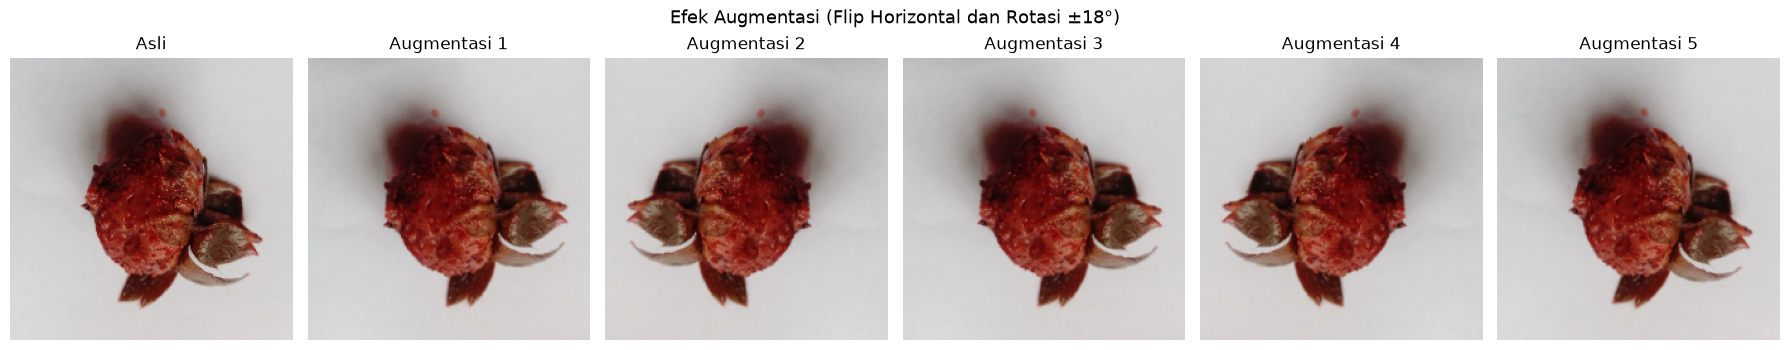

In [7]:
# Satu gambar train yang sama, diaugmentasi 5 kali
dataset_tanpa_augmentasi = buat_dataset("train", augmentasi=False)
gambar_asli = next(iter(dataset_tanpa_augmentasi))[0][:1]  # bentuk (1, 224, 224, 3)

fig, axes = plt.subplots(1, 6, figsize=(18, 3.6))
axes[0].imshow(gambar_asli[0].numpy())
axes[0].set_title("Asli")
for i in range(1, 6):
    axes[i].imshow(lapisan_augmentasi(gambar_asli, training=True)[0].numpy())
    axes[i].set_title(f"Augmentasi {i}")
for sumbu in axes:
    sumbu.axis("off")
fig.suptitle("Efek Augmentasi (Flip Horizontal dan Rotasi ±18°)", fontsize=13)
fig.tight_layout()
simpan_gambar(fig, "pipeline_augmentasi_vs_asli.png")
plt.show()

#### Demo tensor
Tensor adalah array berdimensi banyak yang dipakai TensorFlow untuk semua data. Satu gambar berbentuk `(tinggi, lebar, channel)` atau `(224, 224, 3)`, sedangkan satu batch menambah dimensi di depan menjadi `(jumlah gambar, tinggi, lebar, channel)` atau `(32, 224, 224, 3)`. Label satu batch berbentuk `(32,)`.

Sel berikut menampilkan bentuk (`shape`), tipe data (`dtype`), dan jumlah dimensi (`rank`) gambar, batch, dan label, lalu memeriksa bahwa nilai piksel ada di rentang 0-1. Setelah itu dicoba delapan operasi dasar TensorFlow: rata-rata per channel, slicing, reshape, cast, konversi ke grayscale, rata-rata batch, one-hot label, dan perkalian matriks.

In [8]:
satu_gambar = gambar_batch[0]

print("=== Bentuk dan tipe data ===")
print(f"Satu gambar : shape={satu_gambar.shape}, dtype={satu_gambar.dtype.name}, rank={tf.rank(satu_gambar).numpy()}")
print(f"Satu batch  : shape={gambar_batch.shape}, dtype={gambar_batch.dtype.name}, rank={tf.rank(gambar_batch).numpy()}")
print(f"Label batch : shape={label_batch.shape}, dtype={label_batch.dtype.name}")
print(f"Jumlah elemen satu batch: {tf.size(gambar_batch).numpy():,}")

print("\n=== Rentang nilai piksel (harus 0-1) ===")
print(f"min={tf.reduce_min(gambar_batch).numpy():.3f}  max={tf.reduce_max(gambar_batch).numpy():.3f}  "
      f"rata-rata={tf.reduce_mean(gambar_batch).numpy():.3f}")

print("\n=== Operasi dasar TensorFlow ===")
# 1. Rata-rata per channel (R, G, B) di seluruh batch
rata_channel = tf.reduce_mean(gambar_batch, axis=(0, 1, 2))
print(f"1. Rata-rata channel R,G,B     : {np.round(rata_channel.numpy(), 3)}")

# 2. Slicing: 4 gambar pertama, hanya channel merah
merah = gambar_batch[:4, :, :, 0]
print(f"2. Slicing channel merah 4 gbr : shape={merah.shape}")

# 3. Reshape: ratakan tiap gambar menjadi satu vektor (dipakai sebelum lapisan Dense)
rata = tf.reshape(gambar_batch, (gambar_batch.shape[0], -1))
print(f"3. Reshape (flatten) per gambar: shape={rata.shape}")

# 4. Cast: kembalikan ke 0-255 bertipe uint8
kembali_255 = tf.cast(satu_gambar * 255.0, tf.uint8)
print(f"4. Cast ke uint8               : dtype={kembali_255.dtype.name}, min={tf.reduce_min(kembali_255).numpy()}, max={tf.reduce_max(kembali_255).numpy()}")

# 5. Grayscale: gabungkan 3 channel menjadi 1
abu = tf.image.rgb_to_grayscale(satu_gambar)
print(f"5. Grayscale                   : shape={abu.shape}")

# 6. Gambar rata-rata satu batch
gambar_rata2 = tf.reduce_mean(gambar_batch, axis=0)
print(f"6. Gambar rata-rata batch      : shape={gambar_rata2.shape}")

# 7. One-hot label dan jumlah per kelas dalam batch
one_hot = tf.one_hot(label_batch, depth=len(nama_kelas))
print(f"7. One-hot label               : shape={one_hot.shape}, jumlah gambar per kelas di batch ini = "
      f"{tf.reduce_sum(one_hot, axis=0).numpy().astype(int).tolist()}")

# 8. Perkalian matriks: (32, 150528) x (150528, 4) -> (32, 4)
bobot_acak = tf.random.normal((rata.shape[1], 4), stddev=0.01, seed=BENIH_ACAK)
print(f"8. Matmul                      : {rata.shape} x {bobot_acak.shape} -> {tf.matmul(rata, bobot_acak).shape}")

=== Bentuk dan tipe data ===
Satu gambar : shape=(224, 224, 3), dtype=float32, rank=3
Satu batch  : shape=(32, 224, 224, 3), dtype=float32, rank=4
Label batch : shape=(32,), dtype=int32
Jumlah elemen satu batch: 4,816,896

=== Rentang nilai piksel (harus 0-1) ===
min=0.000  max=1.000  rata-rata=0.610

=== Operasi dasar TensorFlow ===
1. Rata-rata channel R,G,B     : [0.672 0.61  0.546]
2. Slicing channel merah 4 gbr : shape=(4, 224, 224)
3. Reshape (flatten) per gambar: shape=(32, 150528)
4. Cast ke uint8               : dtype=uint8, min=0, max=222
5. Grayscale                   : shape=(224, 224, 1)
6. Gambar rata-rata batch      : shape=(224, 224, 3)
7. One-hot label               : shape=(32, 16), jumlah gambar per kelas di batch ini = [4, 2, 3, 1, 3, 0, 1, 1, 0, 2, 1, 1, 3, 3, 5, 2]
8. Matmul                      : (32, 150528) x (150528, 4) -> (32, 4)


Agar lebih mudah dibayangkan, satu gambar dipecah menjadi tiga channel warna (merah, hijau, biru) dan versi grayscale-nya. Setiap channel berbentuk `(224, 224)` dan grayscale berbentuk `(224, 224, 1)`. Grafik disimpan ke `results/figures/pipeline_demo_tensor.png`.

Grafik disimpan: d:\fruit_freshness_classification\results\figures\pipeline_demo_tensor.png


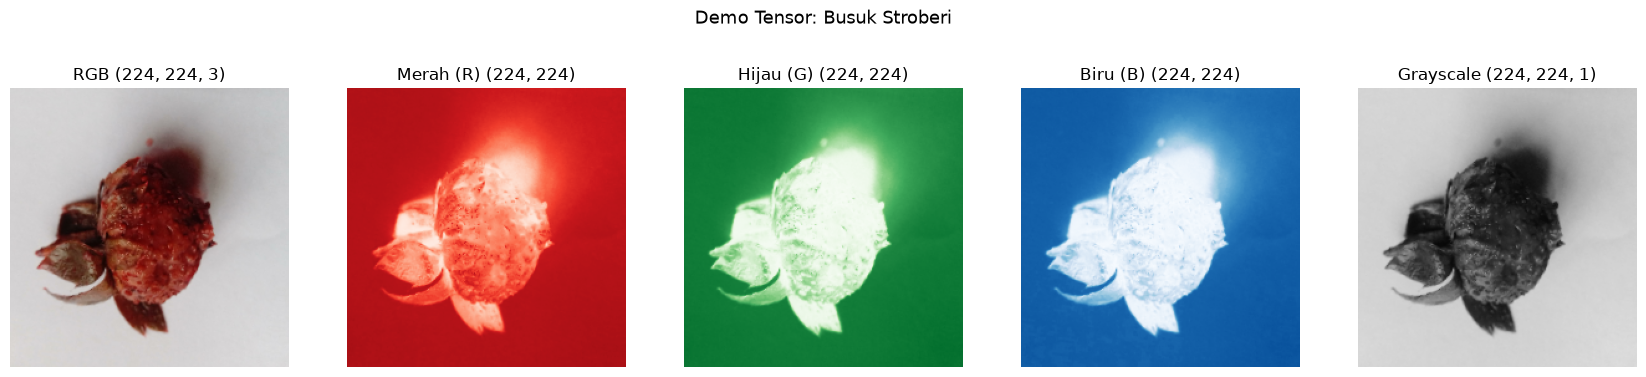

In [10]:
fig, axes = plt.subplots(1, 5, figsize=(17, 3.8))
axes[0].imshow(satu_gambar.numpy())
axes[0].set_title(f"RGB {tuple(satu_gambar.shape)}")
for i, (nama, cmap) in enumerate([("Merah (R)", "Reds"), ("Hijau (G)", "Greens"), ("Biru (B)", "Blues")], start=1):
    axes[i].imshow(satu_gambar[:, :, i - 1].numpy(), cmap=cmap, vmin=0, vmax=1)
    axes[i].set_title(f"{nama} {tuple(satu_gambar[:, :, i - 1].shape)}")
axes[4].imshow(abu[:, :, 0].numpy(), cmap="gray", vmin=0, vmax=1)
axes[4].set_title(f"Grayscale {tuple(abu.shape)}")
for sumbu in axes:
    sumbu.axis("off")
fig.suptitle(f"Demo Tensor: {nama_kelas[int(label_batch[0])]}", fontsize=13)
fig.tight_layout(rect=(0, 0, 1, 0.90))
simpan_gambar(fig, "pipeline_demo_tensor.png")
plt.show()

#### Ringkasan
Input pipeline tf.data sudah siap dipakai untuk pelatihan model:

- `dataset_train`: 2.214 gambar, diacak setiap epoch, diaugmentasi (flip horizontal dan rotasi ±18°), 70 batch.
- `dataset_val` dan `dataset_test`: masing-masing 475 gambar, tanpa pengacakan dan tanpa augmentasi, 15 batch.
- Setiap batch berisi gambar `(32, 224, 224, 3)` bertipe `float32` dengan nilai 0-1 dan label `(32,)` bertipe `int32` dengan nilai 0-15.

Grafik hasil bagian ini ada di `results/figures/`: `pipeline_contoh_batch_train.png`, `pipeline_augmentasi_vs_asli.png`, dan `pipeline_demo_tensor.png`.